In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset, random_split, Subset

from torchvision import transforms
from torchvision.datasets import MNIST

from sklearn.metrics import classification_report, confusion_matrix

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
QUESTION = 2
PICS_DIR = "./figures"
BATCH_SIZE = 128
AE_BATCH_SIZE = 128
EPOCHS_LENET = 50
EPOCHS_AE = 15
LR_LENET = 1e-3
LR_AE = 1e-3
VAL_RATIO = 0.1
DATA_DIR = "./data"

In [5]:
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = x.view(-1, 16 * 4 * 4)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

In [6]:
class SimpleAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(8, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


# Utils

In [7]:
def denormalize(img_tensor, mean=0.1307, std=0.3081):
    return img_tensor * std + mean

In [ ]:
"""
Display a grid of images with optional titles, denormalization, and a global MixUp coefficient, then save the visualization to disk.
"""
def show_images(images, titles=None, n=8, figsize=(14, 3), denorm=False, lam=None):
    plt.figure(figsize=figsize)

    for i in range(min(n, len(images))):
        plt.subplot(1, min(n, len(images)), i + 1)
        img = images[i].detach().cpu()

        if denorm:
            img = denormalize(img)

        plt.imshow(img.squeeze(), cmap="gray")
        plt.axis("off")

        if titles is not None:
            plt.title(str(titles[i]))

    # ---- Global title with lam ----
    if lam is not None:
        title = f"MixUp Batch (λ={lam:.2f})"
    else:
        title = "MixUp Batch"

    plt.suptitle(title, fontsize=14)

    plt.tight_layout(rect=[0, 0, 1, 0.9])

    # ---- Save ----
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

In [ ]:
"""
Visualize original images alongside their augmented counterparts in aligned rows, applying denormalization and re-normalization for correct display, and save the comparison.
"""
def show_side_by_side_same(x, y, mean, std, transform, n=8):
    plt.figure(figsize=(14, 4))

    for i in range(n):
        # original
        plt.subplot(2, n, i + 1)
        img_orig = denormalize(x[i].cpu())
        plt.imshow(img_orig.squeeze(), cmap="gray")
        plt.axis("off")
        plt.title(f"Orig: {y[i].item()}")

        # augmented
        img = x[i].cpu()

        img_denorm = denormalize(img)
        img_aug = transform(img_denorm)

        img_aug = transforms.Normalize((mean,), (std,))(img_aug)

        plt.subplot(2, n, i + 1 + n)
        img_aug_show = denormalize(img_aug)
        plt.imshow(img_aug_show.squeeze(), cmap="gray")
        plt.axis("off")
        plt.title(f"Aug: {y[i].item()}")

    title = "Original vs Augmented (aligned)"
    plt.suptitle(title, fontsize=14)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

In [10]:
def accuracy_from_logits(logits, y):
    preds = logits.argmax(dim=1)
    return (preds == y).float().mean().item()

# MixUp

In [ ]:
"""
Generate mixed samples and paired labels using MixUp by interpolating inputs and shuffling targets with a Beta-distributed coefficient.
"""
def mixup_data(x, y, alpha=0.4):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(device)
    mixed_x = lam * x + (1-lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

In [ ]:
"""
Compute MixUp loss as a weighted combination of losses from paired targets using the mixing coefficient.
"""
def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1-lam) * criterion(pred, y_b)

In [ ]:
"""
Visualize a batch of MixUp samples with paired label annotations and the corresponding mixing coefficient.
"""
def visualize_mixup_batch(loader, alpha=0.4, n=8):
    x, y = next(iter(loader))
    x, y = x.to(device), y.to(device)
    mixed_x, y_a, y_b, lam = mixup_data(x, y, alpha=alpha)
    titles = [f"{int(a)}-{int(b)}" for a, b in zip(y_a[:n], y_b[:n])]
    show_images(mixed_x[:n], titles=titles, n=n, denorm=True, lam=lam)

In [14]:
def plot_history_mixup(history, title="MixUp Training History"):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Validation Loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    ax = plt.subplot(1, 2, 2)
    ax.plot(epochs, history["val_acc"], color="tab:orange", label="Validation Acc")
    ax.set_title(f"{title} - Accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend(loc="best")

    ax.text(
        0.98, 0.05,
        "Train Acc is omitted\nbecause MixUp uses soft labels.",
        transform=ax.transAxes,
        fontsize=9,
        ha="right",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
    )

    plt.tight_layout()

    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)

    plt.show()

# Evaluation + Training

In [15]:
@torch.no_grad()
def evaluate_classifier(model, data_loader, criterion=None):
    model.eval()
    model.to(device)
    if criterion is None:
        criterion = nn.CrossEntropyLoss()
    
    total_loss = 0.0
    total = 0
    correct = 0
    all_preds = []
    all_labels = []

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        total += y.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds==y).sum().item()

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
    
    avg_loss = total_loss / total
    acc = correct / total
    return avg_loss, acc, np.array(all_labels), np.array(all_preds)

In [ ]:
"""
Train a classification model with optional MixUp augmentation, track loss and accuracy over epochs, and evaluate performance on a validation set.
"""
def train_classifier(model, train_loader, val_loader, epochs=5, lr=1e-3, mixup_alpha=None):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_total = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()

            if mixup_alpha is not None:
                x_mixed, y_a, y_b, lam = mixup_data(x, y, alpha=mixup_alpha)
                logits = model(x_mixed)
                loss = mixup_criterion(criterion, logits, y_a, y_b, lam)
            else:
                logits = model(x)
                loss = criterion(logits, y)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            running_total += y.size(0)

            if mixup_alpha is None:
                preds = logits.argmax(dim=1)
                running_correct += (preds == y).sum().item()

        train_loss = running_loss / running_total
        train_acc = running_correct / running_total if mixup_alpha is None else np.nan

        val_loss, val_acc, _, _ = evaluate_classifier(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if mixup_alpha is None:
            print(
                f"Epoch [{epoch+1}/{epochs}] | "
                f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
                f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
            )
        else:
            print(
                f"Epoch [{epoch+1}/{epochs}] | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
            )

    return history

# Results

In [17]:
def plot_history(history, title="Training History"):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Validation Loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    if not np.isnan(history["train_acc"]).all():
        plt.plot(epochs, history["train_acc"], label="Train Acc")
    plt.plot(epochs, history["val_acc"], label="Validation Acc")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [ ]:
"""
Evaluate a trained classifier on a test set, print detailed performance metrics, and visualize the confusion matrix.
"""
def report_results(model, data_loader, model_name="Model"):
    criterion = nn.CrossEntropyLoss()
    loss, acc, y_true, y_pred = evaluate_classifier(model, data_loader, criterion)

    print(f"\n===== {model_name} =====")
    print(f"Test Loss: {loss:.4f}")
    print(f"Test Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 7))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.colorbar()

    num_classes = cm.shape[0]
    for i in range(num_classes):
        for j in range(num_classes):
            plt.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black",
                fontsize=9
            )

    plt.xticks(range(num_classes))
    plt.yticks(range(num_classes))
    plt.tight_layout()
    title = f"Confusion Matrix - {model_name}"
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

    return {
        "model_name": model_name,
        "test_loss": loss,
        "test_acc": acc
    }

In [19]:
def plot_ae_history(history, title="AE Training Loss"):
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, len(history["loss"]) + 1), history["loss"])
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [20]:
@torch.no_grad()
def visualize_ae_reconstructions(ae_model, data_loader, n=8):
    ae_model.eval()

    x, y = next(iter(data_loader))
    x = x.to(device)
    x_rec = ae_model(x)

    x = x[:n].cpu()
    x_rec = x_rec[:n].cpu()
    y = y[:n].cpu()

    fig, axes = plt.subplots(2, n, figsize=(14, 4.8))

    # ---- Row 1: Original ----
    for i in range(n):
        img = denormalize(x[i])
        axes[0, i].imshow(img.squeeze(), cmap="gray")
        axes[0, i].axis("off")
        axes[0, i].set_title(f"{y[i].item()}", fontsize=11, pad=6)

    # ---- Row 2: Reconstructed ----
    for i in range(n):
        img = denormalize(x_rec[i])
        axes[1, i].imshow(img.squeeze(), cmap="gray")
        axes[1, i].axis("off")
        axes[1, i].set_title(f"{y[i].item()}", fontsize=11, pad=6)

    # ---- Global and row titles ----
    title = "AE Reconstructions"
    fig.suptitle(title, fontsize=16, y=0.98)
    fig.text(0.5, 0.90, "Original Images", ha="center", fontsize=13)
    fig.text(0.5, 0.46, "Reconstructed Images", ha="center", fontsize=13)

    # more controlled spacing than tight_layout alone
    plt.subplots_adjust(top=0.82, bottom=0.08, hspace=0.38, wspace=0.12)

    # ---- Save ----
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

# Autoencoder augmentation

In [ ]:
"""
Define a custom dataset that wraps image tensors and labels for indexed access during training and evaluation.
"""
class TensorDatasetCustom(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.images[idx], int(self.labels[idx])

In [ ]:
"""
Generate a new dataset by passing inputs through an autoencoder to obtain reconstructed samples while preserving original labels.
"""
@torch.no_grad()
def build_ae_augmented_dataset(base_loader, ae_model, device):
    ae_model.eval()
    ae_model.to(device)

    all_images = []
    all_labels = []

    for x, y in base_loader:
        x = x.to(device)
        x_rec = ae_model(x).cpu()

        all_images.append(x_rec)
        all_labels.append(y)

    all_images = torch.cat(all_images, dim=0)
    all_labels = torch.cat(all_labels, dim=0)

    return TensorDatasetCustom(all_images, all_labels)

In [ ]:
"""
Train an autoencoder to reconstruct inputs by minimizing reconstruction loss and track training loss over epochs.
"""
def train_ae(model, train_loader, epochs=5, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    history = {"loss":[]}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        total = 0
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            x_rec = model(x)
            loss = criterion(x_rec, x)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            total += x.size(0)
        
        epoch_loss = running_loss / total
        history['loss'].append(epoch_loss)
        print(f"AE Epoch [{epoch+1}/{epochs}] | Reconstruction Loss: {epoch_loss:.6f}")
    
    return history

# Dataset and loaders

In [24]:
mean, std = 0.1307, 0.3081

transform_base = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])

transform_routine_aug = transforms.Compose([
    transforms.RandomRotation(degrees=20),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])

In [25]:
train_base = MNIST(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=transform_base
)

train_routine = MNIST(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=transform_routine_aug
)

test_base = MNIST(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=transform_base
)

In [26]:
num_train = len(train_base)
indices = torch.randperm(num_train, generator=torch.Generator().manual_seed(42)).tolist()

val_size = int(VAL_RATIO * num_train)
train_indices = indices[val_size:]
val_indices = indices[:val_size]

train_base_split = Subset(train_base, train_indices)
train_routine_split = Subset(train_routine, train_indices)
val_base = Subset(train_base, val_indices)

In [27]:
train_loader_base = DataLoader(
    train_base_split,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

train_loader_routine = DataLoader(
    train_routine_split,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_base,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_base,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# For AE, train only on clean training split
ae_train_loader = DataLoader(
    train_base_split,
    batch_size=AE_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

Original vs Augmented (aligned):


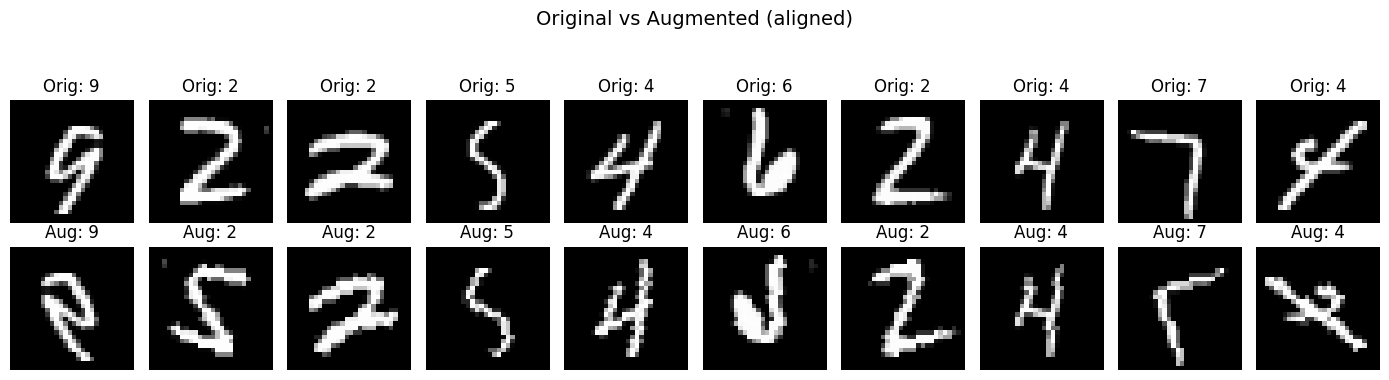

In [43]:
x_orig, y_orig = next(iter(train_loader_base))

aug_only_transform = transforms.Compose([
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip(0.5),
])

print("Original vs Augmented (aligned):")
show_side_by_side_same(x_orig, y_orig, mean, std, aug_only_transform, n=10)

# Baseline LeNet

================ BASELINE LENET ================

Epoch [1/50] | Train Loss: 0.3658 | Train Acc: 0.8922 | Val Loss: 0.1335 | Val Acc: 0.9617
Epoch [2/50] | Train Loss: 0.0875 | Train Acc: 0.9728 | Val Loss: 0.0712 | Val Acc: 0.9767
Epoch [3/50] | Train Loss: 0.0615 | Train Acc: 0.9804 | Val Loss: 0.0563 | Val Acc: 0.9810
Epoch [4/50] | Train Loss: 0.0487 | Train Acc: 0.9844 | Val Loss: 0.0591 | Val Acc: 0.9817
Epoch [5/50] | Train Loss: 0.0413 | Train Acc: 0.9869 | Val Loss: 0.0503 | Val Acc: 0.9860
Epoch [6/50] | Train Loss: 0.0339 | Train Acc: 0.9896 | Val Loss: 0.0648 | Val Acc: 0.9802
Epoch [7/50] | Train Loss: 0.0316 | Train Acc: 0.9901 | Val Loss: 0.0568 | Val Acc: 0.9823
Epoch [8/50] | Train Loss: 0.0265 | Train Acc: 0.9915 | Val Loss: 0.0454 | Val Acc: 0.9867
Epoch [9/50] | Train Loss: 0.0226 | Train Acc: 0.9929 | Val Loss: 0.0451 | Val Acc: 0.9848
Epoch [10/50] | Train Loss: 0.0195 | Train Acc: 0.9936 | Val Loss: 0.0492 | Val Acc: 0.9857
Epoch [11/50] | Train Loss: 0.0187 | Tr

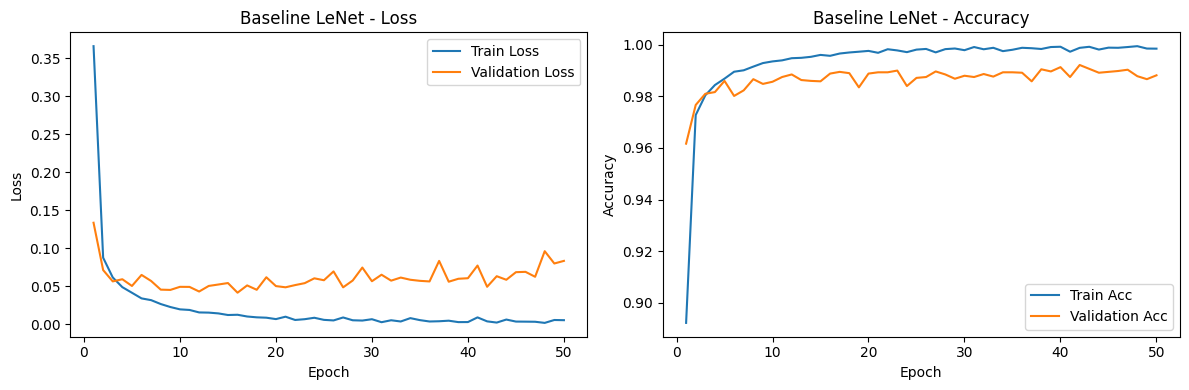


===== Baseline LeNet =====
Test Loss: 0.0668
Test Accuracy: 0.9887

Classification Report:
              precision    recall  f1-score   support

           0     0.9898    0.9929    0.9913       980
           1     0.9947    0.9947    0.9947      1135
           2     0.9865    0.9913    0.9889      1032
           3     0.9891    0.9861    0.9876      1010
           4     0.9918    0.9837    0.9877       982
           5     0.9909    0.9809    0.9859       892
           6     0.9855    0.9927    0.9891       958
           7     0.9893    0.9864    0.9878      1028
           8     0.9857    0.9918    0.9887       974
           9     0.9832    0.9851    0.9842      1009

    accuracy                         0.9887     10000
   macro avg     0.9887    0.9886    0.9886     10000
weighted avg     0.9887    0.9887    0.9887     10000



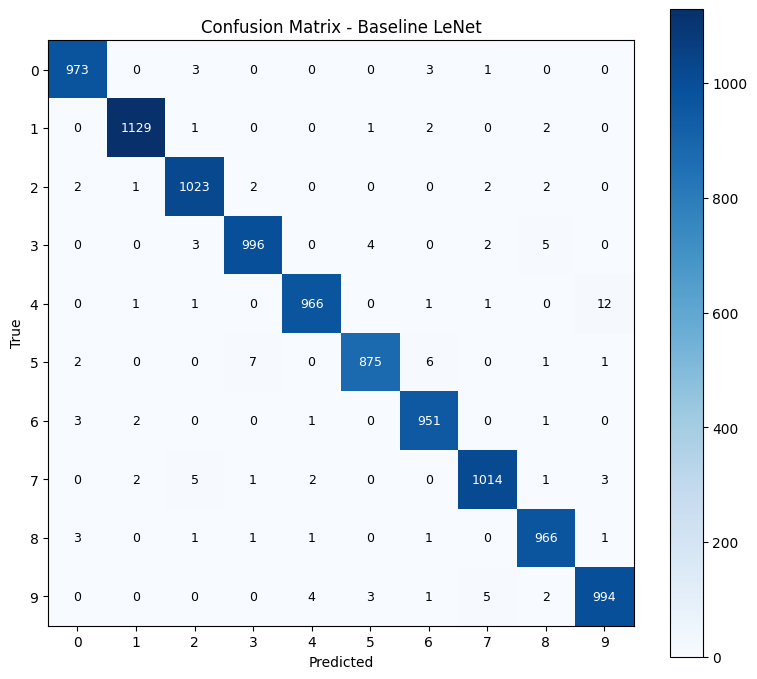

In [29]:
print("================ BASELINE LENET ================\n")
baseline_model = LeNet()
history_baseline = train_classifier(
    baseline_model,
    train_loader_base,
    val_loader,
    epochs=EPOCHS_LENET,
    lr=LR_LENET
)
plot_history(history_baseline, title="Baseline LeNet")
baseline_result = report_results(baseline_model, test_loader, model_name="Baseline LeNet")

# Routine Augmentation (rotation + flip)

================ ROUTINE AUGMENTATION ================

Epoch [1/50] | Train Loss: 0.6193 | Train Acc: 0.8002 | Val Loss: 0.2737 | Val Acc: 0.9103
Epoch [2/50] | Train Loss: 0.2534 | Train Acc: 0.9195 | Val Loss: 0.1543 | Val Acc: 0.9520
Epoch [3/50] | Train Loss: 0.1848 | Train Acc: 0.9410 | Val Loss: 0.1303 | Val Acc: 0.9585
Epoch [4/50] | Train Loss: 0.1508 | Train Acc: 0.9522 | Val Loss: 0.1011 | Val Acc: 0.9692
Epoch [5/50] | Train Loss: 0.1277 | Train Acc: 0.9597 | Val Loss: 0.0843 | Val Acc: 0.9732
Epoch [6/50] | Train Loss: 0.1145 | Train Acc: 0.9631 | Val Loss: 0.1022 | Val Acc: 0.9678
Epoch [7/50] | Train Loss: 0.1048 | Train Acc: 0.9666 | Val Loss: 0.0802 | Val Acc: 0.9742
Epoch [8/50] | Train Loss: 0.0952 | Train Acc: 0.9696 | Val Loss: 0.0787 | Val Acc: 0.9743
Epoch [9/50] | Train Loss: 0.0880 | Train Acc: 0.9721 | Val Loss: 0.0692 | Val Acc: 0.9795
Epoch [10/50] | Train Loss: 0.0844 | Train Acc: 0.9726 | Val Loss: 0.0746 | Val Acc: 0.9757
Epoch [11/50] | Train Loss: 0.077

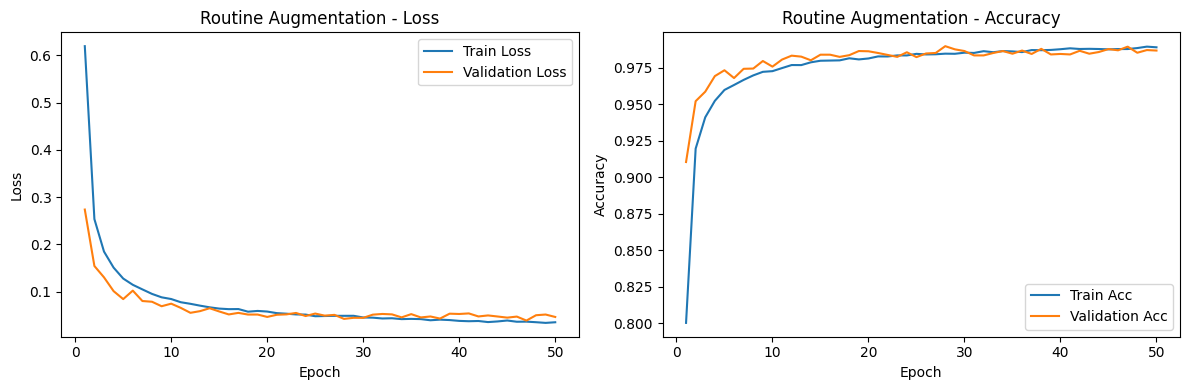


===== Routine Augmentation =====
Test Loss: 0.0487
Test Accuracy: 0.9859

Classification Report:
              precision    recall  f1-score   support

           0     0.9859    0.9969    0.9914       980
           1     0.9930    0.9947    0.9938      1135
           2     0.9795    0.9729    0.9762      1032
           3     0.9920    0.9842    0.9881      1010
           4     0.9879    0.9939    0.9909       982
           5     0.9733    0.9821    0.9777       892
           6     0.9781    0.9770    0.9775       958
           7     0.9893    0.9883    0.9888      1028
           8     0.9876    0.9846    0.9861       974
           9     0.9900    0.9832    0.9866      1009

    accuracy                         0.9859     10000
   macro avg     0.9857    0.9858    0.9857     10000
weighted avg     0.9859    0.9859    0.9859     10000



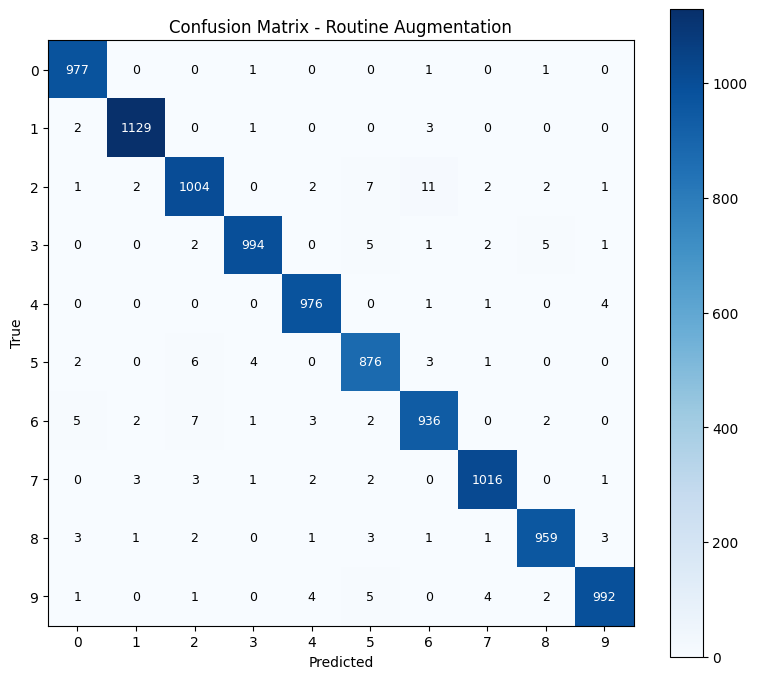

In [30]:
print("================ ROUTINE AUGMENTATION ================\n")
routine_model = LeNet()
history_routine = train_classifier(
    routine_model,
    train_loader_routine,
    val_loader,
    epochs=EPOCHS_LENET,
    lr=LR_LENET
)
plot_history(history_routine, title="Routine Augmentation")
routine_result = report_results(routine_model, test_loader, model_name="Routine Augmentation")

# Autoencoder-based Augmentation

================ AUTOENCODER TRAINING ================



AE Epoch [1/15] | Reconstruction Loss: 0.605828
AE Epoch [2/15] | Reconstruction Loss: 0.490019
AE Epoch [3/15] | Reconstruction Loss: 0.483940
AE Epoch [4/15] | Reconstruction Loss: 0.481752
AE Epoch [5/15] | Reconstruction Loss: 0.480511
AE Epoch [6/15] | Reconstruction Loss: 0.479611
AE Epoch [7/15] | Reconstruction Loss: 0.478839
AE Epoch [8/15] | Reconstruction Loss: 0.478179
AE Epoch [9/15] | Reconstruction Loss: 0.477633
AE Epoch [10/15] | Reconstruction Loss: 0.477150
AE Epoch [11/15] | Reconstruction Loss: 0.476772
AE Epoch [12/15] | Reconstruction Loss: 0.476437
AE Epoch [13/15] | Reconstruction Loss: 0.476129
AE Epoch [14/15] | Reconstruction Loss: 0.475849
AE Epoch [15/15] | Reconstruction Loss: 0.475604


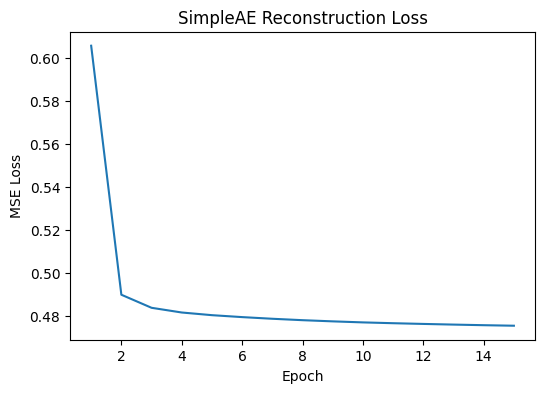

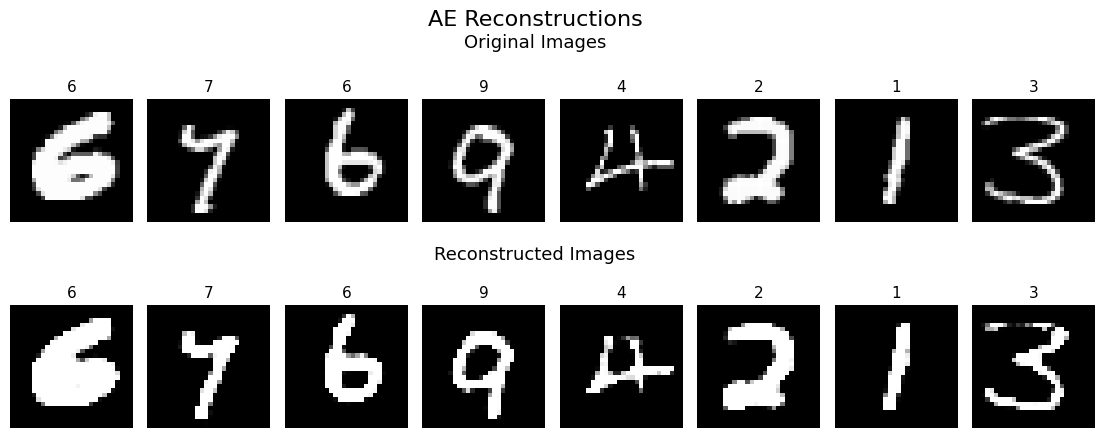

In [31]:
print("================ AUTOENCODER TRAINING ================\n")
ae_model = SimpleAE()
ae_history = train_ae(
    ae_model,
    ae_train_loader,
    epochs=EPOCHS_AE,
    lr=LR_AE
)
plot_ae_history(ae_history, title="SimpleAE Reconstruction Loss")
visualize_ae_reconstructions(ae_model, val_loader, n=8)

In [32]:
print("Building AE-augmented dataset...")

base_loader_for_ae_gen = DataLoader(
    train_base_split,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

ae_augmented_dataset = build_ae_augmented_dataset(
    base_loader_for_ae_gen,
    ae_model,
    device
)

combined_train_dataset = ConcatDataset([
    train_base_split,
    ae_augmented_dataset
])

train_loader_ae_aug = DataLoader(
    combined_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

Building AE-augmented dataset...


================ AE-BASED AUGMENTATION ================

Epoch [1/50] | Train Loss: 0.2773 | Train Acc: 0.9244 | Val Loss: 0.0992 | Val Acc: 0.9725
Epoch [2/50] | Train Loss: 0.0901 | Train Acc: 0.9751 | Val Loss: 0.0763 | Val Acc: 0.9822
Epoch [3/50] | Train Loss: 0.0656 | Train Acc: 0.9811 | Val Loss: 0.0665 | Val Acc: 0.9852
Epoch [4/50] | Train Loss: 0.0523 | Train Acc: 0.9842 | Val Loss: 0.0667 | Val Acc: 0.9858
Epoch [5/50] | Train Loss: 0.0437 | Train Acc: 0.9865 | Val Loss: 0.0537 | Val Acc: 0.9882
Epoch [6/50] | Train Loss: 0.0378 | Train Acc: 0.9884 | Val Loss: 0.0523 | Val Acc: 0.9887
Epoch [7/50] | Train Loss: 0.0323 | Train Acc: 0.9899 | Val Loss: 0.0708 | Val Acc: 0.9853
Epoch [8/50] | Train Loss: 0.0304 | Train Acc: 0.9906 | Val Loss: 0.0737 | Val Acc: 0.9862
Epoch [9/50] | Train Loss: 0.0263 | Train Acc: 0.9916 | Val Loss: 0.0723 | Val Acc: 0.9868
Epoch [10/50] | Train Loss: 0.0210 | Train Acc: 0.9930 | Val Loss: 0.0625 | Val Acc: 0.9888
Epoch [11/50] | Train Loss: 0.02

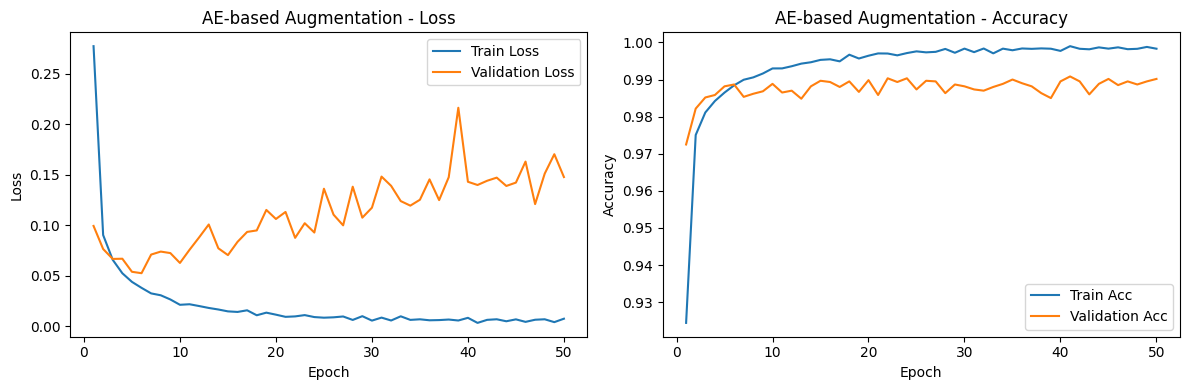


===== AE-based Augmentation =====
Test Loss: 0.1141
Test Accuracy: 0.9911

Classification Report:
              precision    recall  f1-score   support

           0     0.9929    0.9969    0.9949       980
           1     0.9913    0.9982    0.9947      1135
           2     0.9903    0.9932    0.9918      1032
           3     0.9911    0.9921    0.9916      1010
           4     0.9898    0.9929    0.9914       982
           5     0.9844    0.9888    0.9866       892
           6     0.9979    0.9854    0.9916       958
           7     0.9951    0.9844    0.9897      1028
           8     0.9928    0.9918    0.9923       974
           9     0.9851    0.9861    0.9856      1009

    accuracy                         0.9911     10000
   macro avg     0.9911    0.9910    0.9910     10000
weighted avg     0.9911    0.9911    0.9911     10000



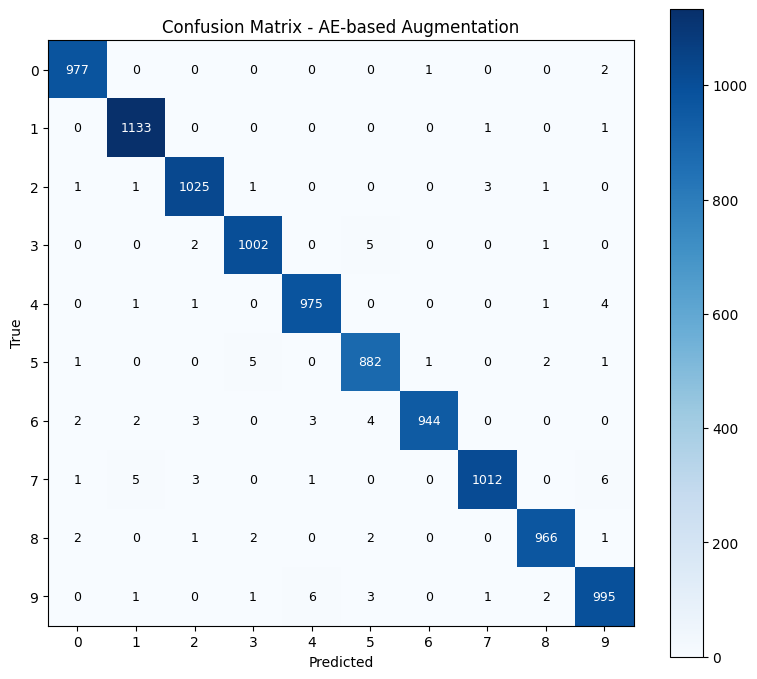

In [33]:
print("================ AE-BASED AUGMENTATION ================\n")
ae_aug_model = LeNet()
history_ae_aug = train_classifier(
    ae_aug_model,
    train_loader_ae_aug,
    val_loader,
    epochs=EPOCHS_LENET,
    lr=LR_LENET
)
plot_history(history_ae_aug, title="AE-based Augmentation")
ae_aug_result = report_results(ae_aug_model, test_loader, model_name="AE-based Augmentation")


# MixUp AUGMENTATION

Visualizing MixUp samples:


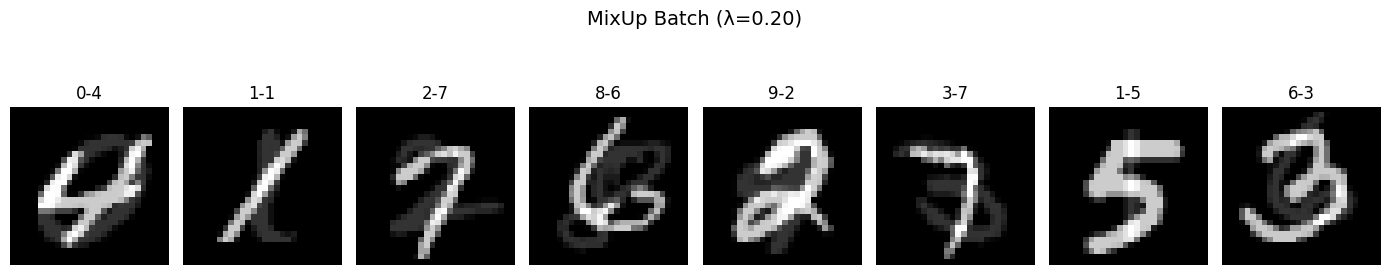

In [53]:
print("Visualizing MixUp samples:")
visualize_mixup_batch(train_loader_base, alpha=0.4, n=8)

================ MIXUP AUGMENTATION ================

Epoch [1/50] | Train Loss: 0.9002 | Val Loss: 0.2182 | Val Acc: 0.9552
Epoch [2/50] | Train Loss: 0.6838 | Val Loss: 0.1461 | Val Acc: 0.9677
Epoch [3/50] | Train Loss: 0.6055 | Val Loss: 0.1177 | Val Acc: 0.9767
Epoch [4/50] | Train Loss: 0.5999 | Val Loss: 0.1020 | Val Acc: 0.9778
Epoch [5/50] | Train Loss: 0.5896 | Val Loss: 0.0991 | Val Acc: 0.9822
Epoch [6/50] | Train Loss: 0.5648 | Val Loss: 0.0779 | Val Acc: 0.9823
Epoch [7/50] | Train Loss: 0.5350 | Val Loss: 0.0798 | Val Acc: 0.9820
Epoch [8/50] | Train Loss: 0.5437 | Val Loss: 0.0883 | Val Acc: 0.9843
Epoch [9/50] | Train Loss: 0.5353 | Val Loss: 0.0791 | Val Acc: 0.9825
Epoch [10/50] | Train Loss: 0.5589 | Val Loss: 0.0768 | Val Acc: 0.9850
Epoch [11/50] | Train Loss: 0.5334 | Val Loss: 0.0909 | Val Acc: 0.9860
Epoch [12/50] | Train Loss: 0.5067 | Val Loss: 0.0704 | Val Acc: 0.9885
Epoch [13/50] | Train Loss: 0.5199 | Val Loss: 0.0769 | Val Acc: 0.9885
Epoch [14/50] | Tra

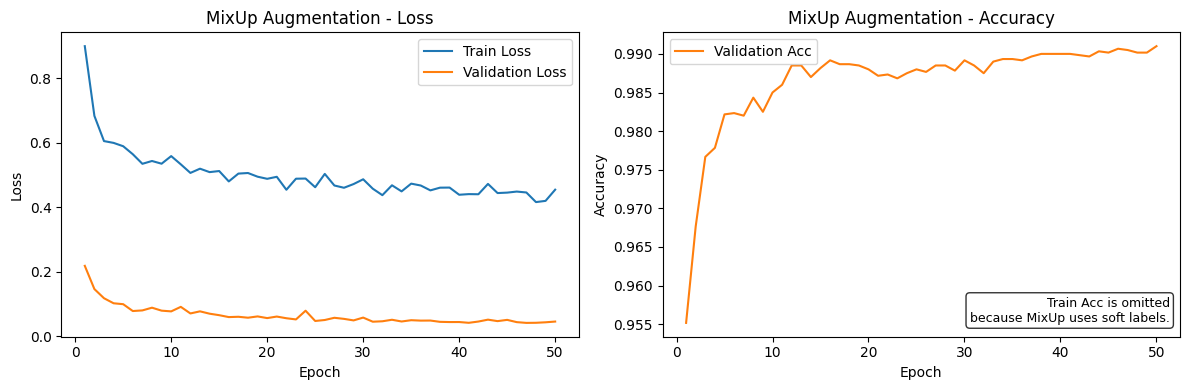


===== MixUp Augmentation =====
Test Loss: 0.0426
Test Accuracy: 0.9907

Classification Report:
              precision    recall  f1-score   support

           0     0.9939    0.9980    0.9959       980
           1     0.9973    0.9930    0.9951      1135
           2     0.9903    0.9942    0.9923      1032
           3     0.9862    0.9931    0.9896      1010
           4     0.9909    0.9959    0.9934       982
           5     0.9832    0.9865    0.9849       892
           6     0.9968    0.9854    0.9911       958
           7     0.9835    0.9883    0.9859      1028
           8     0.9918    0.9887    0.9902       974
           9     0.9920    0.9832    0.9876      1009

    accuracy                         0.9907     10000
   macro avg     0.9906    0.9906    0.9906     10000
weighted avg     0.9907    0.9907    0.9907     10000



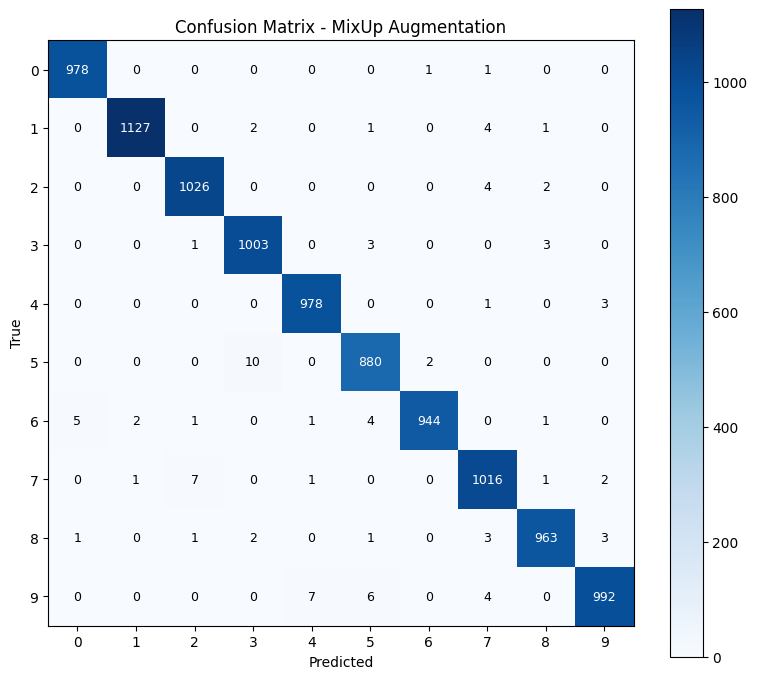

In [35]:
print("================ MIXUP AUGMENTATION ================\n")
mixup_model = LeNet()
history_mixup = train_classifier(
    mixup_model,
    train_loader_base,
    val_loader,
    epochs=EPOCHS_LENET,
    lr=LR_LENET,
    mixup_alpha=0.4
)
plot_history_mixup(history_mixup, title="MixUp Augmentation")
mixup_result = report_results(mixup_model, test_loader, model_name="MixUp Augmentation")

# Final comparison

In [36]:
results = [
    baseline_result,
    routine_result,
    ae_aug_result,
    mixup_result
]

print("================ FINAL COMPARISON ================\n")
for r in results:
    print(f"{r['model_name']}: Test Acc = {r['test_acc']:.4f}, Test Loss = {r['test_loss']:.4f}")

================ FINAL COMPARISON ================

Baseline LeNet: Test Acc = 0.9887, Test Loss = 0.0668
Routine Augmentation: Test Acc = 0.9859, Test Loss = 0.0487
AE-based Augmentation: Test Acc = 0.9911, Test Loss = 0.1141
MixUp Augmentation: Test Acc = 0.9907, Test Loss = 0.0426
